In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.metrics import recall_score, precision_score, f1_score, roc_auc_score, average_precision_score, precision_recall_curve, roc_curve, auc

In [2]:
# Set visualization style
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Upload data_cardiovascular_risk.csv directly to Colab before running this cell
df_raw = pd.read_csv('data_cardiovascular_risk.csv')

# Drop arbitrary index column
if 'id' in df_raw.columns:
    df_raw = df_raw.drop(columns=['id'])

print(f"Dataset successfully loaded: {df_raw.shape[0]} rows, {df_raw.shape[1]} features.")

Dataset successfully loaded: 3390 rows, 16 features.


In [3]:
df = df_raw.copy()

# 1. Binary Mapping
df['sex'] = df['sex'].map({'M': 1, 'F': 0})
df['is_smoking'] = df['is_smoking'].map({'YES': 1, 'NO': 0})

# Logical fix: Non-smokers smoke 0 cigarettes/day
df.loc[df['is_smoking'] == 0, 'cigsPerDay'] = 0.0

# 2. Clinical Risk Interaction Features
df['pulse_pressure'] = df['sysBP'] - df['diaBP']
df['MAP'] = df['diaBP'] + (1.0 / 3.0) * (df['sysBP'] - df['diaBP'])
df['atherogenic_idx'] = df['totChol'] / df['BMI']
df['smoking_load'] = (df['cigsPerDay'] / 20.0) * np.maximum(df['age'] - 18, 0)

# Separate features and target
X = df.drop(columns=['TenYearCHD'])
y = df['TenYearCHD']

print("Feature Engineering Complete.")
print(f"Total input features: {X.shape[1]}")
print(f"Target Distribution: Negative = {(y==0).sum()} ({np.mean(y==0)*100:.1f}%), Positive = {(y==1).sum()} ({np.mean(y==1)*100:.1f}%)")

Feature Engineering Complete.
Total input features: 19
Target Distribution: Negative = 2879 (84.9%), Positive = 511 (15.1%)


In [4]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'Logistic Regression (Cost-Weighted)': LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'),
    'Random Forest (Balanced)': RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced'),
    'Gradient Boosting (Standard)': GradientBoostingClassifier(n_estimators=150, random_state=42),
    'HistGradientBoosting (Cost-Weighted)': HistGradientBoostingClassifier(random_state=42, class_weight='balanced')
}

benchmark_results = []

for name, model in models.items():
    rec_list, prec_list, f1_list, roc_list, pr_list = [], [], [], [], []

    for train_idx, val_idx in skf.split(X, y):
        X_train, X_val = X.iloc[train_idx].copy(), X.iloc[val_idx].copy()
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        # Fit imputer and scaler ONLY on training folds (No Data Leakage)
        imputer = KNNImputer(n_neighbors=5)
        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(imputer.fit_transform(X_train))
        X_val_scaled = scaler.transform(imputer.transform(X_val))

        model.fit(X_train_scaled, y_train)

        y_pred = model.predict(X_val_scaled)
        y_proba = model.predict_proba(X_val_scaled)[:, 1]

        rec_list.append(recall_score(y_val, y_pred))
        prec_list.append(precision_score(y_val, y_pred, zero_division=0))
        f1_list.append(f1_score(y_val, y_pred))
        roc_list.append(roc_auc_score(y_val, y_proba))
        pr_list.append(average_precision_score(y_val, y_proba))

    benchmark_results.append({
        'Model Architecture': name,
        'Recall (Sensitivity)': np.mean(rec_list),
        'Precision': np.mean(prec_list),
        'F1-Score': np.mean(f1_list),
        'ROC-AUC': np.mean(roc_list),
        'PR-AUC': np.mean(pr_list)
    })

res_df = pd.DataFrame(benchmark_results)
print("=== Baseline Leak-Free 5-Fold Stratified CV Results ===")
display(res_df)

=== Baseline Leak-Free 5-Fold Stratified CV Results ===


,Model Architecture,Recall (Sensitivity),Precision,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression (Cost-Weighted),0.651818,0.257128,0.368602,0.726873,0.354919
1,Random Forest (Balanced),0.031334,0.647619,0.059513,0.686182,0.297326
2,Gradient Boosting (Standard),0.117457,0.448945,0.185828,0.686885,0.303289
3,HistGradientBoosting (Cost-Weighted),0.270055,0.285422,0.277110,0.664402,0.291324


In [5]:
# Cross-validated out-of-fold predictions for threshold tuning & ROC/PR curves
all_probas, all_y = [], []

for train_idx, val_idx in skf.split(X, y):
    X_train, X_val = X.iloc[train_idx].copy(), X.iloc[val_idx].copy()
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    imputer = KNNImputer(n_neighbors=5)
    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(imputer.fit_transform(X_train))
    X_val_scaled = scaler.transform(imputer.transform(X_val))

    lr = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
    lr.fit(X_train_scaled, y_train)

    all_probas.extend(lr.predict_proba(X_val_scaled)[:, 1])
    all_y.extend(y_val)

all_probas = np.array(all_probas)
all_y = np.array(all_y)

# Precision-Recall & ROC Curve Calculations
precisions, recalls, thresholds = precision_recall_curve(all_y, all_probas)
fpr, tpr, _ = roc_curve(all_y, all_probas)
roc_auc = auc(fpr, tpr)
pr_auc = average_precision_score(all_y, all_probas)

# Optimal Threshold based on F1
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
best_thresh = thresholds[best_idx]

print(f"Optimal Probability Threshold: {best_thresh:.4f}")
print(f"At Threshold {best_thresh:.4f} -> Recall: {recalls[best_idx]:.4f}, Precision: {precisions[best_idx]:.4f}, Max F1: {f1_scores[best_idx]:.4f}")

Optimal Probability Threshold: 0.5804
At Threshold 0.5804 -> Recall: 0.5421, Precision: 0.3098, Max F1: 0.3943


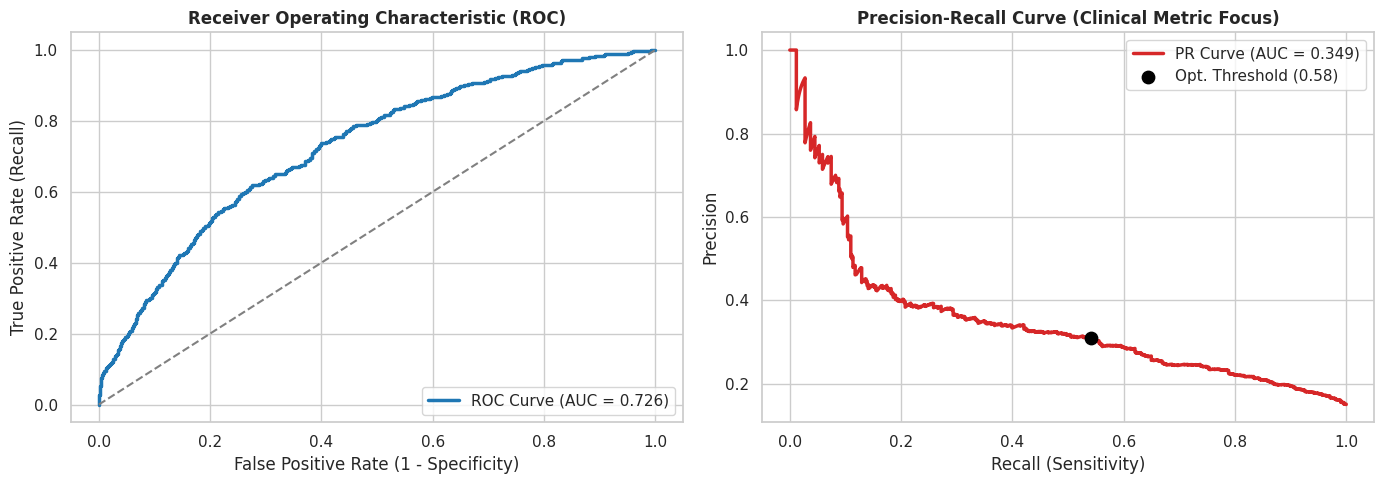

In [6]:
# Plot 1: ROC & Precision-Recall Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(fpr, tpr, color='#1f77b4', lw=2.5, label=f'ROC Curve (AUC = {roc_auc:.3f})')
axes[0].plot([0, 1], [0, 1], color='gray', linestyle='--')
axes[0].set_xlabel('False Positive Rate (1 - Specificity)')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].set_title('Receiver Operating Characteristic (ROC)', fontsize=12, fontweight='bold')
axes[0].legend(loc="lower right")

axes[1].plot(recalls, precisions, color='#d62728', lw=2.5, label=f'PR Curve (AUC = {pr_auc:.3f})')
axes[1].scatter(recalls[best_idx], precisions[best_idx], color='black', s=80, zorder=5, label=f'Opt. Threshold ({best_thresh:.2f})')
axes[1].set_xlabel('Recall (Sensitivity)')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve (Clinical Metric Focus)', fontsize=12, fontweight='bold')
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.savefig('chd_roc_pr_curves.png', dpi=300)
plt.show()

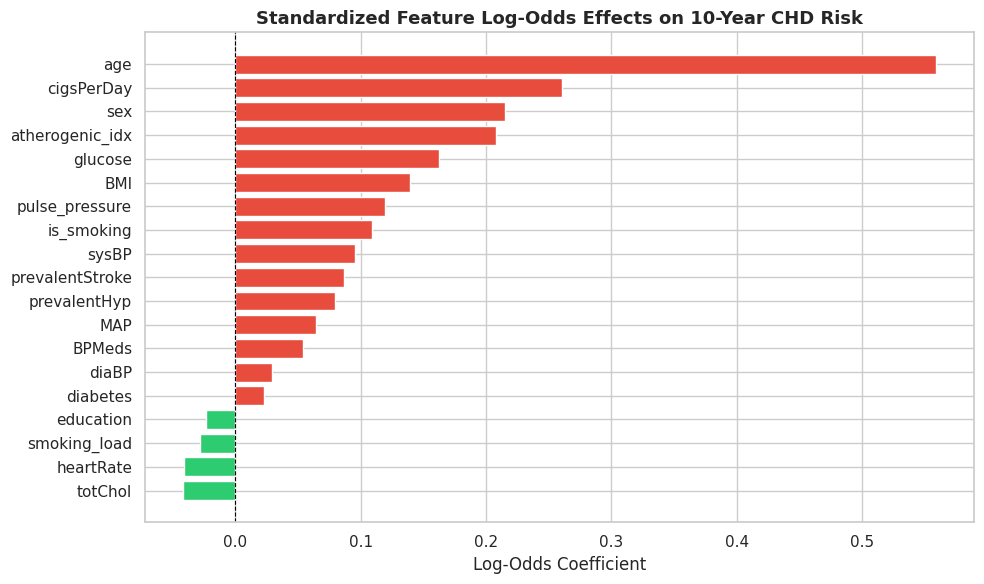

In [7]:
# Plot 2: Standardized Feature Coefficients (Odds Ratios)
imputer_full = KNNImputer(n_neighbors=5)
scaler_full = StandardScaler()
X_full_scaled = pd.DataFrame(scaler_full.fit_transform(imputer_full.fit_transform(X)), columns=X.columns)

lr_full = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
lr_full.fit(X_full_scaled, y)

coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Log_Odds': lr_full.coef_[0],
    'Odds_Ratio': np.exp(lr_full.coef_[0])
}).sort_values(by='Log_Odds', ascending=True)

plt.figure(figsize=(10, 6))
colors = ['#2ecc71' if x < 0 else '#e74c3c' for x in coef_df['Log_Odds']]
plt.barh(coef_df['Feature'], coef_df['Log_Odds'], color=colors)
plt.axvline(x=0, color='black', linestyle='--', linewidth=0.8)
plt.title('Standardized Feature Log-Odds Effects on 10-Year CHD Risk', fontsize=13, fontweight='bold')
plt.xlabel('Log-Odds Coefficient')
plt.tight_layout()
plt.savefig('chd_feature_importance.png', dpi=300)
plt.show()